In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from prophet import Prophet
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


1. SETUP TRAINING DATA AND LOAD Prophet MODEL

In [3]:
# 1. Load Data
df = pd.read_csv("../dataset/preprocessed_data_unscaled.csv")
df['Date'] = pd.to_datetime(df['Date'])
df = df.rename(columns={'Date': 'ds', 'PM25': 'y'})
df = df[['ds', 'y']].dropna()

# 2. Load Saved Prophet Model
print("Loading saved Prophet model...")
model = joblib.load('../Predict Model/prophet_model.pkl')

Loading saved Prophet model...


In [4]:
# Generate Prophet Predictions on Historical Data
y_max = df['y'].max()
df['cap'] = y_max * 1.2
df['floor'] = 0

forecast_prophet = model.predict(df)
prophet_trend = forecast_prophet['yhat'].values
df['prophet_pred'] = prophet_trend

In [5]:
# Prepare features for hybrid models
df['year'] = df['ds'].dt.year
df['month'] = df['ds'].dt.month
df['day'] = df['ds'].dt.day
df['dayofweek'] = df['ds'].dt.dayofweek
df['weekofyear'] = df['ds'].dt.isocalendar().week.astype(int)
features = ['year', 'month', 'day', 'dayofweek', 'weekofyear']

In [6]:
#OUTPUT FUNCTION FOR MODEL PERFORMACE
def evaluate_performance(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    
    print(f"\n{model_name} Performance:")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R²: {r2:.4f}")
    print(f"MAPE: {mape:.4f}%")
    
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R²': r2}

## Hybrid Model
- Original Model: Prophet

## A) Prophet + Random Forest Regressor

1. TRAIN AND FIT RF HYBRID MODEL

In [7]:
# Calculate Residuals (The part Prophet missed)
df['residual'] = df['y'] - forecast_prophet['yhat']

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(df[features], df['residual'])

# Make predictions
rf_residuals_pred = rf.predict(df[features])
rf_hybrid_predictions = forecast_prophet['yhat'] + rf_residuals_pred

print("Hybrid training complete.")


Hybrid training complete.


2. EVALUATE RF HYBRID MODEL

In [8]:
rf_hybrid_perf = evaluate_performance(df['y'], rf_hybrid_predictions, "Prophet + Random Forest")
prophet_perf = evaluate_performance(df['y'], forecast_prophet['yhat'], "Prophet Only")


Prophet + Random Forest Performance:
MSE: 48.3378
RMSE: 6.9525
MAE: 4.4729
R²: 0.9517
MAPE: 13.0030%

Prophet Only Performance:
MSE: 623.6651
RMSE: 24.9733
MAE: 16.7001
R²: 0.3770
MAPE: 47.1482%


3. TIME SERIES PLOT (Actual vs Predicted)

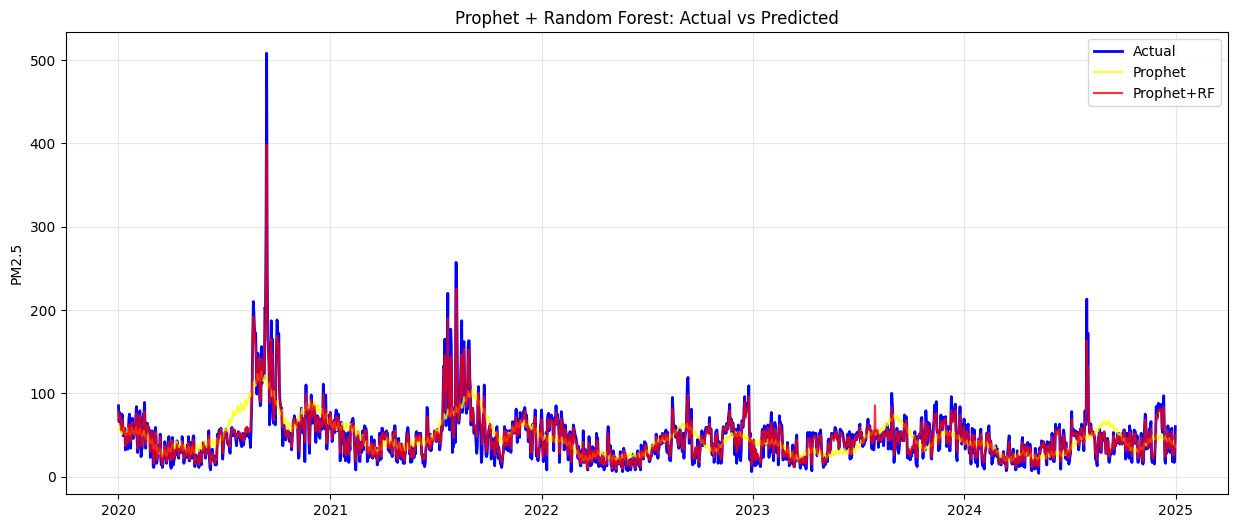

In [9]:
plt.figure(figsize=(15, 6))
plt.plot(df['ds'], df['y'], label='Actual', color='blue', linewidth=2)
plt.plot(df['ds'], forecast_prophet['yhat'], label='Prophet', color='yellow', alpha=0.8)
plt.plot(df['ds'], rf_hybrid_predictions, label='Prophet+RF', color='red', alpha=0.8)
plt.ylabel('PM2.5')
plt.title('Prophet + Random Forest: Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)


4. FORECAST 5 YEARS

In [10]:
print("\nGENERATING 5-YEAR FORECAST...")
# Create Future Dataframe (5 Years)
future = model.make_future_dataframe(periods=1825)
future['cap'] = y_max * 1.2
future['floor'] = 0

# Get Prophet Forecast components
forecast_future = model.predict(future)

# Prepare Future Features for RF
future['year'] = future['ds'].dt.year
future['month'] = future['ds'].dt.month
future['day'] = future['ds'].dt.day
future['dayofweek'] = future['ds'].dt.dayofweek
future['weekofyear'] = future['ds'].dt.isocalendar().week.astype(int)
# Predict Residuals with RF
future_residuals = rf.predict(future[features])

# Combine: Prophet Forecast + RF Correction
forecast_future['yhat_rf_hybrid'] = forecast_future['yhat'] + future_residuals

# Filter for only future dates for plotting
future_only = forecast_future[forecast_future['ds'] > df['ds'].max()]


GENERATING 5-YEAR FORECAST...


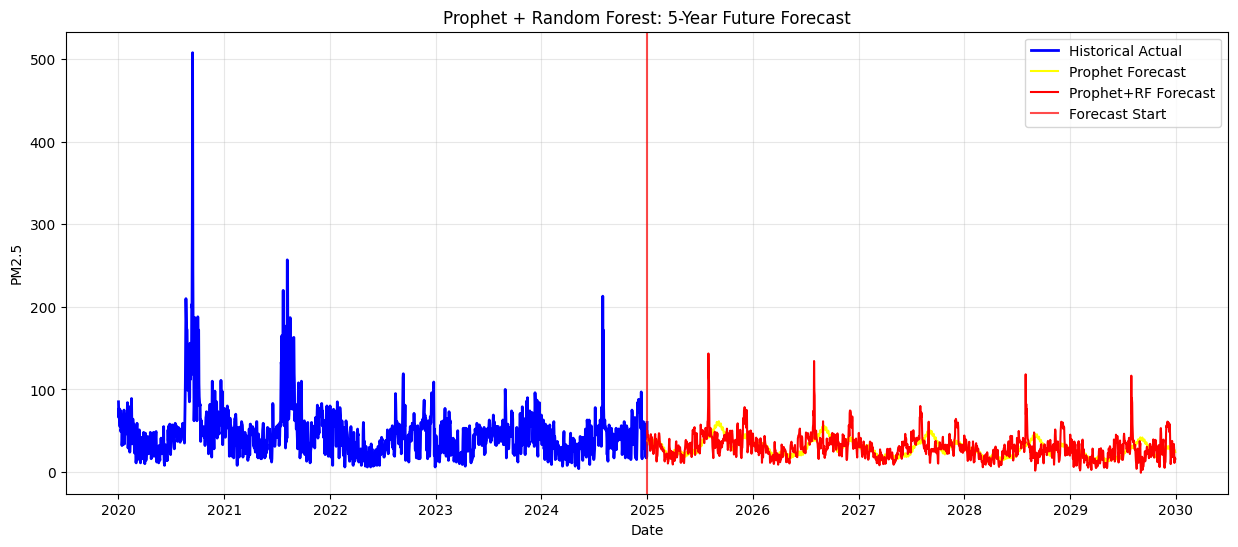

In [11]:
plt.figure(figsize=(15, 6))
plt.plot(df['ds'], df['y'], label='Historical Actual', color='blue', linewidth=2)
plt.plot(future_only['ds'], future_only['yhat'], label='Prophet Forecast', color='yellow')
plt.plot(future_only['ds'], future_only['yhat_rf_hybrid'], label='Prophet+RF Forecast', color='red')
plt.axvline(x=df['ds'].max(), color='red', linestyle='-', alpha=0.7, label='Forecast Start')
plt.xlabel('Date')
plt.ylabel('PM2.5')
plt.title('Prophet + Random Forest: 5-Year Future Forecast')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## B) Prophet + LGBM

In [12]:
import lightgbm as lgb

1. TRAIN AND FIT LGBM HYBRID MODEL

In [13]:
# Calculate residuals
residuals = df['y'].values - forecast_prophet['yhat'].values
df['residual'] = residuals

# Prepare additional features
df['dayofyear'] = df['ds'].dt.dayofyear
df['quarter'] = df['ds'].dt.quarter
df['is_weekend'] = (df['ds'].dt.dayofweek >= 5).astype(int)
df['month_sin'] = np.sin(2 * np.pi * df['month']/12)
df['month_cos'] = np.cos(2 * np.pi * df['month']/12)
df['day_sin'] = np.sin(2 * np.pi * df['day']/31)
df['day_cos'] = np.cos(2 * np.pi * df['day']/31)

lgb_features = features + ['dayofyear', 'quarter', 'is_weekend', 'month_sin', 'month_cos', 'day_sin', 'day_cos']

In [14]:
# Train and Fit Hybrid Model
print("2. TRAINING LIGHTGBM ON RESIDUALS...")
lgb_model = lgb.LGBMRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    subsample=0.8,
    colsample_bytree=0.8
)
lgb_model.fit(df[lgb_features], df['residual'])

2. TRAINING LIGHTGBM ON RESIDUALS...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000141 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 448
[LightGBM] [Info] Number of data points in the train set: 1827, number of used features: 12
[LightGBM] [Info] Start training from score 0.117220
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No

LGBMRegressor(colsample_bytree=0.8, max_depth=6, random_state=42, subsample=0.8)

2. EVALUATE LGBM HYBRID MODEL

In [15]:
# Make predictions
lgb_residuals_pred = lgb_model.predict(df[lgb_features])
lgb_hybrid_predictions = forecast_prophet['yhat'] + lgb_residuals_pred

print("LightGBM training complete.")

# Output Performance
print("\n3. MODEL PERFORMANCE:")
lgb_hybrid_perf = evaluate_performance(df['y'], lgb_hybrid_predictions, "Prophet + LightGBM")


LightGBM training complete.

3. MODEL PERFORMANCE:

Prophet + LightGBM Performance:
MSE: 279.0018
RMSE: 16.7033
MAE: 11.3211
R²: 0.7213
MAPE: 33.9337%


3. TIME SERIES PLOT (Actual vs Predicted)

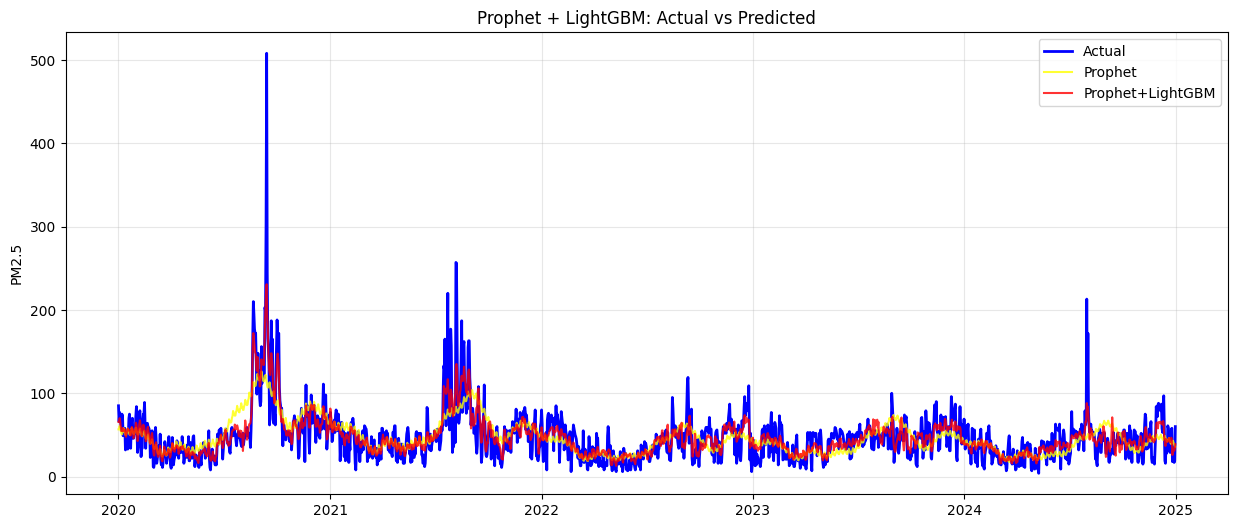

In [16]:
plt.figure(figsize=(15, 6))
plt.plot(df['ds'], df['y'], label='Actual', color='blue', linewidth=2)
plt.plot(df['ds'], forecast_prophet['yhat'], label='Prophet', color='yellow', alpha=0.8)
plt.plot(df['ds'], lgb_hybrid_predictions, label='Prophet+LightGBM', color='red', alpha=0.8)
plt.ylabel('PM2.5')
plt.title('Prophet + LightGBM: Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)

4. FORECAST 5 YEARS

In [17]:
# Prepare Future Features for LightGBM
future_features = future.copy()
future_features['year'] = future_features['ds'].dt.year
future_features['month'] = future_features['ds'].dt.month
future_features['day'] = future_features['ds'].dt.day
future_features['dayofweek'] = future_features['ds'].dt.dayofweek
future_features['weekofyear'] = future_features['ds'].dt.isocalendar().week.astype(int)

# Add the same additional features we used for training
future_features['dayofyear'] = future_features['ds'].dt.dayofyear
future_features['quarter'] = future_features['ds'].dt.quarter
future_features['is_weekend'] = (future_features['ds'].dt.dayofweek >= 5).astype(int)
future_features['month_sin'] = np.sin(2 * np.pi * future_features['month']/12)
future_features['month_cos'] = np.cos(2 * np.pi * future_features['month']/12)
future_features['day_sin'] = np.sin(2 * np.pi * future_features['day']/31)
future_features['day_cos'] = np.cos(2 * np.pi * future_features['day']/31)

In [18]:
# Predict future residuals with LightGBM
future_residuals_lgb = lgb_model.predict(future_features[lgb_features])

# Create hybrid forecast
future_hybrid_lgb = forecast_future[forecast_future['ds'] > df['ds'].max()].copy()
future_hybrid_lgb['yhat_lgb_hybrid'] = future_hybrid_lgb['yhat'] + future_residuals_lgb[len(df):]

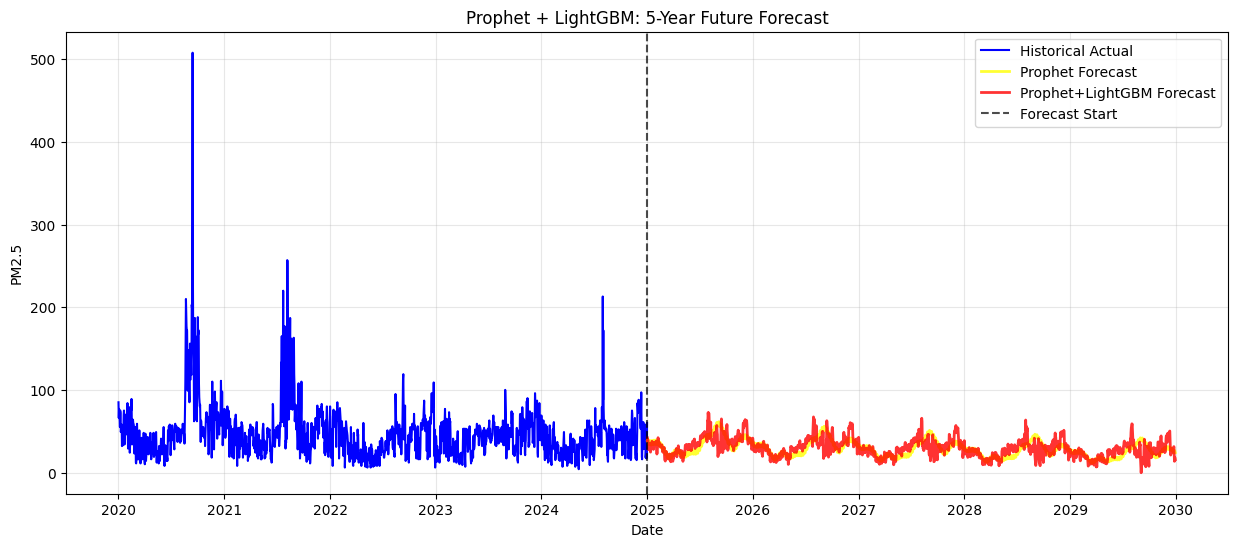

In [19]:
plt.figure(figsize=(15, 6))
plt.plot(df['ds'], df['y'], label='Historical Actual', color='blue')
plt.plot(future_hybrid_lgb['ds'], future_hybrid_lgb['yhat'], label='Prophet Forecast', color='yellow', linestyle='-', linewidth=2, alpha=0.8)
plt.plot(future_hybrid_lgb['ds'], future_hybrid_lgb['yhat_lgb_hybrid'], label='Prophet+LightGBM Forecast', color='red', linestyle='-', linewidth=2, alpha=0.8)
plt.axvline(x=df['ds'].max(), color='black', linestyle='--', alpha=0.7, label='Forecast Start')
plt.xlabel('Date')
plt.ylabel('PM2.5')
plt.title('Prophet + LightGBM: 5-Year Future Forecast')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## C) Prophet + LSTM

In [20]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

1. SETUP TRAINING DATA FOR LSTM HYBRID MODEL

In [21]:
# Calculate residuals for LSTM
residuals = df['y'].values - forecast_prophet['yhat'].values

# Prepare data for LSTM
def prepare_lstm_data(data, lookback=30):
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled_data = scaler.fit_transform(data.reshape(-1, 1))
    X, y = [], []
    for i in range(lookback, len(scaled_data)):
        X.append(scaled_data[i-lookback:i, 0])
        y.append(scaled_data[i, 0])
    return np.array(X), np.array(y), scaler

lookback = 30
X, y, scaler = prepare_lstm_data(residuals, lookback)

In [22]:
# Split data
split_idx = int(0.8 * len(X))
X_train, X_val = X[:split_idx], X[split_idx:]
y_train, y_val = y[:split_idx], y[split_idx:]

# Reshape for LSTM
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)


2. TRAIN AND FIT LSTM HYBRID MODEL

In [23]:
lstm_model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(lookback, 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])
lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Train model
history = lstm_model.fit(
    X_train, y_train,
    batch_size=32,
    epochs=50,
    validation_data=(X_val, y_val),
    verbose=0
)
print("LSTM training complete.")

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM training complete.


3. EVALUATE LSTM HYBRID MODEL

In [24]:
# Make predictions
train_residuals_pred_scaled = lstm_model.predict(X_train)
val_residuals_pred_scaled = lstm_model.predict(X_val)

# Inverse transform predictions
def inverse_transform(scaled_data, scaler):
    dummy = np.zeros((len(scaled_data), 1))
    dummy[:, 0] = scaled_data.flatten()
    return scaler.inverse_transform(dummy)[:, 0]

train_residuals_pred = inverse_transform(train_residuals_pred_scaled, scaler)
val_residuals_pred = inverse_transform(val_residuals_pred_scaled, scaler)

# Combine all predictions
all_residuals_pred = np.concatenate([np.zeros(lookback), train_residuals_pred, val_residuals_pred])

lstm_hybrid_predictions = forecast_prophet['yhat'] + all_residuals_pred

# Output Performance
lstm_hybrid_perf = evaluate_performance(df['y'], lstm_hybrid_predictions, "Prophet + LSTM")

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

Prophet + LSTM Performance:
MSE: 333.7689
RMSE: 18.2693
MAE: 11.6966
R²: 0.6666
MAPE: 33.5885%


4. TIME SERIES PLOT (Actual vs Predicted)

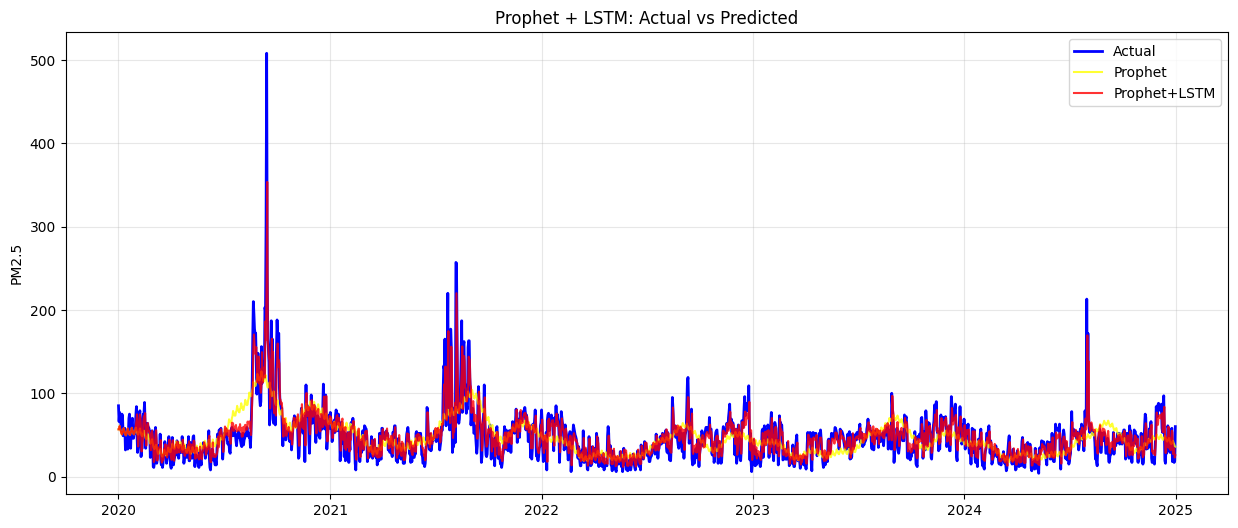

In [25]:
plt.figure(figsize=(15, 6))
plt.plot(df['ds'], df['y'], label='Actual', color='blue', linewidth=2)
plt.plot(df['ds'], forecast_prophet['yhat'], label='Prophet', color='yellow', alpha=0.8)
plt.plot(df['ds'], lstm_hybrid_predictions, label='Prophet+LSTM', color='red', alpha=0.8)
plt.ylabel('PM2.5')
plt.title('Prophet + LSTM: Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)

5. FORECAST 5 YEARS

In [26]:
# Create future dataframe
future = model.make_future_dataframe(periods=1825)
future['cap'] = y_max * 1.2
future['floor'] = 0

# Get Prophet forecast
forecast_future = model.predict(future)

# For LSTM future residuals, we'll use the mean of recent residuals as placeholder
future_residuals_lstm = np.full(len(future), np.mean(residuals[-30:]))

forecast_future['yhat_lstm_hybrid'] = forecast_future['yhat'] + future_residuals_lstm

# Filter for only future dates
future_only = forecast_future[forecast_future['ds'] > df['ds'].max()]


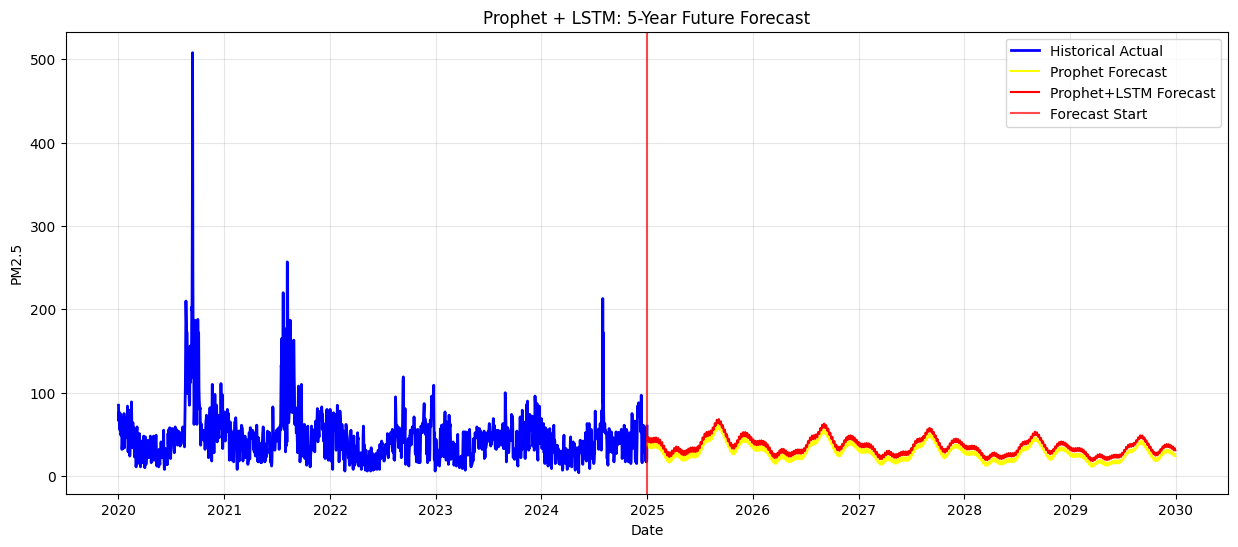

In [27]:
plt.figure(figsize=(15, 6))
plt.plot(df['ds'], df['y'], label='Historical Actual', color='blue', linewidth=2)
plt.plot(future_only['ds'], future_only['yhat'], label='Prophet Forecast', color='yellow')
plt.plot(future_only['ds'], future_only['yhat_lstm_hybrid'], label='Prophet+LSTM Forecast', color='red')
plt.axvline(x=df['ds'].max(), color='red', linestyle='-', alpha=0.7, label='Forecast Start')
plt.xlabel('Date')
plt.ylabel('PM2.5')
plt.title('Prophet + LSTM: 5-Year Future Forecast')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## COMPARISON PERFORMANCE BETWEEN THREE HYBRID MODELS

In [28]:
# 1. Combine performance dictionaries into a list
model_results = [
    rf_hybrid_perf,
    lgb_hybrid_perf,
    lstm_hybrid_perf
]
# 2. Define the model names for the index
model_names = [
    "Prophet + Random Forest",
    "Prophet + LightGBM",
    "Prophet + LSTM"
]
# 3. Create the DataFrame
results_table = pd.DataFrame(model_results, index=model_names)

# 4. Display the table
print("       ====== Hybrid Model Performance Comparison ======")
display(results_table)


       ====== Hybrid Model Performance Comparison ======


,MSE,RMSE,MAE,R²
Prophet + Random Forest,48.337821,6.952541,4.472947,0.951713
Prophet + LightGBM,279.001839,16.703348,11.321142,0.721292
Prophet + LSTM,333.768932,18.269344,11.696583,0.666582


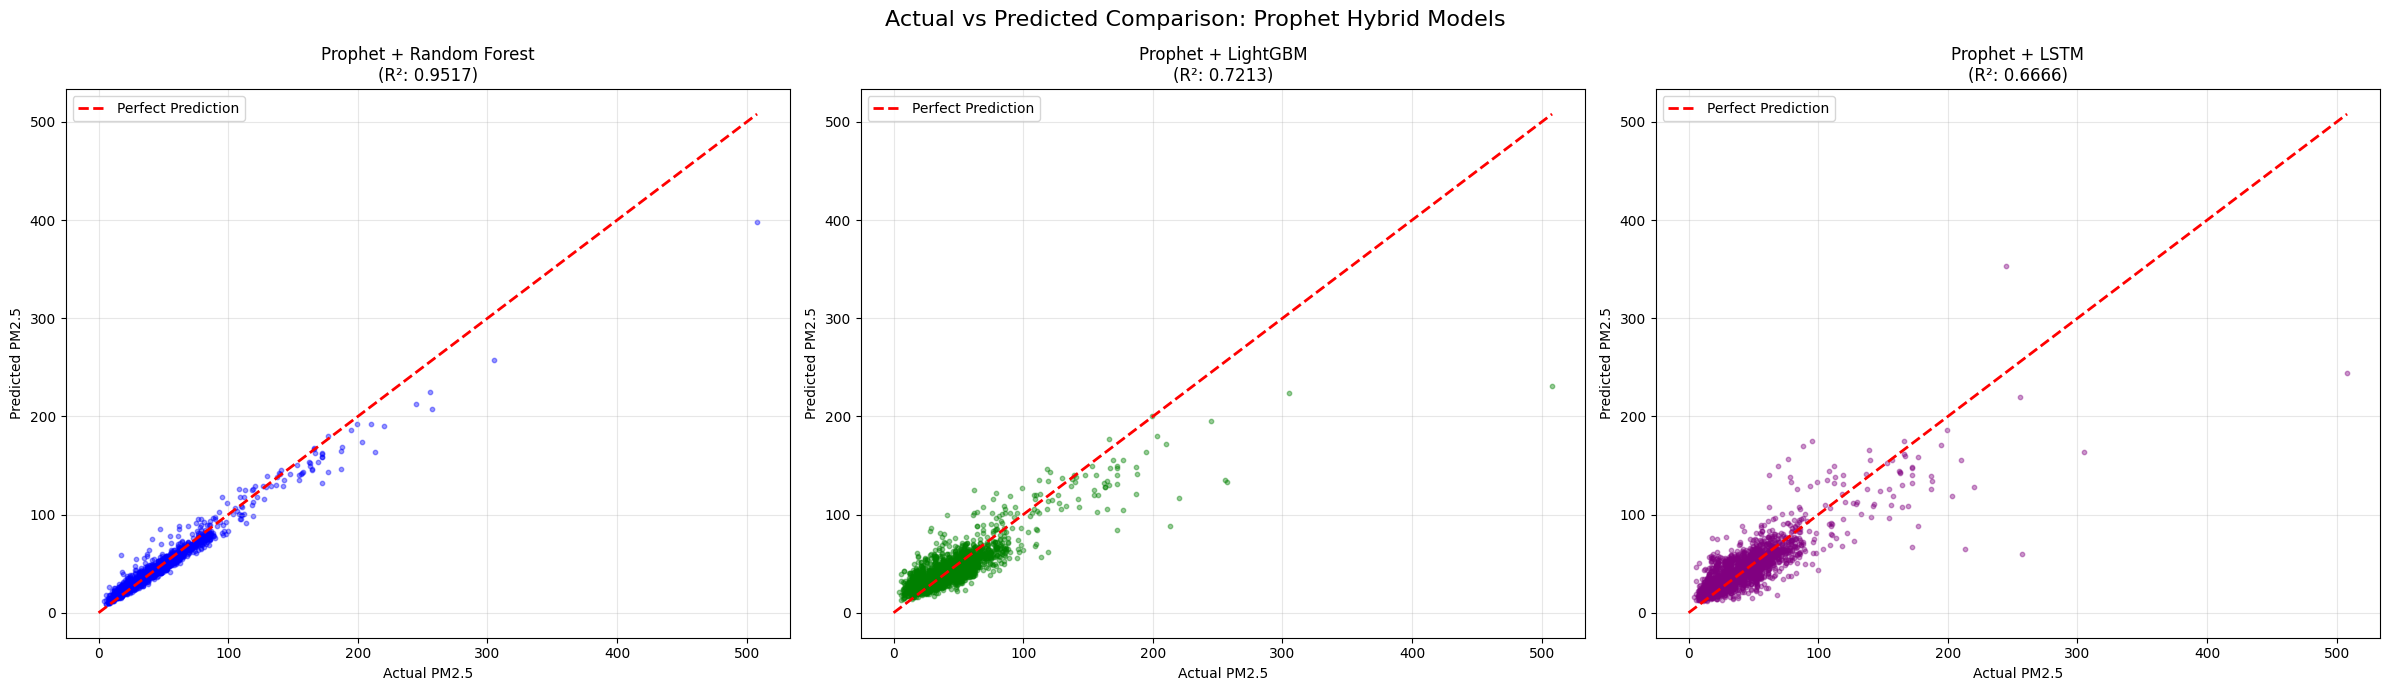

In [29]:
# Set figure size
plt.figure(figsize=(24, 7))
plt.suptitle('Actual vs Predicted Comparison: Prophet Hybrid Models', fontsize=16)

# Define common min/max for the red line
y_min = min(df['y'].min(), 0)
y_max = df['y'].max()

# --- Plot 1: Prophet + Random Forest ---
plt.subplot(1, 3, 1)  # Activate the 1st plot
plt.scatter(df['y'], rf_hybrid_predictions, alpha=0.4, color='blue', s=10)
plt.plot([y_min, y_max], [y_min, y_max], 'r--', lw=2, label='Perfect Prediction')
plt.title(f'Prophet + Random Forest\n(R²: {rf_hybrid_perf["R²"]:.4f})', fontsize=12)
plt.xlabel('Actual PM2.5')
plt.ylabel('Predicted PM2.5')
plt.legend()
plt.grid(True, alpha=0.3)

# --- Plot 2: Prophet + LightGBM ---
plt.subplot(1, 3, 2)  # Activate the 2nd plot
plt.scatter(df['y'], lgb_hybrid_predictions, alpha=0.4, color='green', s=10)
plt.plot([y_min, y_max], [y_min, y_max], 'r--', lw=2, label='Perfect Prediction')
plt.title(f'Prophet + LightGBM\n(R²: {lgb_hybrid_perf["R²"]:.4f})', fontsize=12)
plt.xlabel('Actual PM2.5')
plt.ylabel('Predicted PM2.5')
plt.legend()
plt.grid(True, alpha=0.3)

# --- Plot 3: Prophet + LSTM ---
plt.subplot(1, 3, 3)  # Activate the 3rd plot
plt.scatter(df['y'], lstm_hybrid_predictions, alpha=0.4, color='purple', s=10)
plt.plot([y_min, y_max], [y_min, y_max], 'r--', lw=2, label='Perfect Prediction')
plt.title(f'Prophet + LSTM\n(R²: {lstm_hybrid_perf["R²"]:.4f})', fontsize=12)
plt.xlabel('Actual PM2.5')
plt.ylabel('Predicted PM2.5')
plt.legend()
plt.grid(True, alpha=0.3)

# Adjust layout and show
plt.tight_layout()
plt.show()